# Binary fates: mass ratio vs Mach number

For every binary that forms, this notebook records its mass ratio $q$ and Mach number at formation, and what
happened to it: **merged**, **ionized**, or **still bound** when the run ends.

The standard run outputs (`population_*.txt`) don't keep binaries at formation or ionizations, so each run is
re-simulated from its own `settings.ini`. It uses the canonical `mcfacts.simulation.run_galaxy` timeline and the
same galaxy seeds, with one extra actor appended at the end of the active timeline. The re-run should therefore
match the original run, and section 3 checks that against the saved merger population.

**Inputs:** run folders in `RUN_DIRS` (default `runs/` and `runs_02/` at the repo root).
**Outputs:** `binary_fates.csv` saved inside each run folder (reused on later runs unless `RERUN = True`), and the
figure in `FIG_DIR`.

Mach number follows the original stalling-runs plot: the binary's relative orbital speed over the local sound
speed, $\mathcal{M} = \sqrt{G M_{\rm bin} / a_{\rm bin}} \,/\, c_s(r)$. The table also stores each component's Mach number
about the centre of mass (`mach_1`, `mach_2`), which is what the analytical drag uses.

## 1. Setup

In [1]:
import contextlib
import io
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from tqdm.auto import tqdm

from mcfacts.fiducial_plots import make_gen_masks
from mcfacts.objects.disk import AGNDisk
from mcfacts.objects.galaxy import Galaxy
from mcfacts.objects.populators import SingleBlackHolePopulator, SingleStarPopulator
from mcfacts.objects.snapshot import IniSnapshotHandler
from mcfacts.objects.timeline import TimelineActor
from mcfacts.simulation import run_galaxy
from mcfacts.utilities.constants import C_SI, G_SI, M_SUN_KG
from mcfacts.vis import plotting, styles

plt.style.use("mcfacts.vis.mcfacts_figures")

In [2]:
# Run folders to analyse (each needs a settings.ini written by McFACTS)
RUN_DIRS = ["../../runs", "../../runs_02"]

FATES_FILE = "binary_fates.csv"   # written inside each run folder
RERUN = False                     # True: re-simulate even if binary_fates.csv already exists
N_GALAXIES = None                 # None: all galaxies in the run's settings; an int for a quick test

FIG_DIR = "./plots/binary_fates"
FORMATS = ("png", "pdf")

## 2. Recorder and re-run

`BinaryFateRecorder` runs after every other actor in the active timeline:

* A binary that is new this step gets a row with its state at formation.
* A binary that was present last step and is gone now was either merged or ionized. Those are the only two
  ways `blackholes_binary` loses entries. It counts as merged if its `unique_id` is in the merged array, otherwise
  ionized.
* After the last step, any binary still present is labelled `bound`.

`Galaxy.run` deep-copies the timeline, so the recorder returns itself from `__deepcopy__` to keep writing into the
shared `records` dict.

In [3]:
class BinaryFateRecorder(TimelineActor):
    def __init__(self, records, galaxy_id, settings):
        super().__init__("Binary Fate Recorder", settings)
        self.records = records    # (galaxy_id, unique_id) -> row dict, shared across galaxies
        self.galaxy_id = galaxy_id
        self.alive = set()        # binaries present at the end of the previous step

    def __deepcopy__(self, memo):
        return self

    def perform(self, timestep, timestep_length, time_passed, filing_cabinet, agn_disk, random_generator):
        sm = self.settings
        time_now = time_passed + timestep_length

        ids_now = set()
        if sm.bbh_array_name in filing_cabinet:
            binaries = filing_cabinet.get_array(sm.bbh_array_name)
            ids_now = set(binaries.unique_id)

            new = np.array([uid not in self.alive for uid in binaries.unique_id], dtype=bool)
            if new.any():
                self._record_formation(binaries, new, agn_disk, time_now)

        gone = self.alive - ids_now
        if gone:
            merged_ids = set()
            if sm.bbh_merged_array_name in filing_cabinet:
                merged_ids = set(filing_cabinet.get_array(sm.bbh_merged_array_name).unique_id)
            for uid in gone:
                row = self.records[(self.galaxy_id, uid)]
                row["fate"] = "merged" if uid in merged_ids else "ionized"
                row["time_end"] = time_now

        self.alive = ids_now

    def _record_formation(self, binaries, new, agn_disk, time_now):
        sm = self.settings
        r_g = G_SI * sm.smbh_mass * M_SUN_KG / C_SI ** 2

        m1, m2 = binaries.mass[new], binaries.mass_2[new]
        m_tot = (m1 + m2) * M_SUN_KG
        sep = binaries.bin_sep[new] * r_g
        sound_speed = agn_disk.disk_sound_speed(binaries.orb_a[new])
        v_rel = np.sqrt(G_SI * m_tot / sep)

        for k, uid in enumerate(binaries.unique_id[new]):
            self.records[(self.galaxy_id, uid)] = dict(
                galaxy_id=self.galaxy_id,
                unique_id=str(uid),
                time_formed=time_now,
                mass_1=m1[k],
                mass_2=m2[k],
                q=min(m1[k], m2[k]) / max(m1[k], m2[k]),
                gen_1=binaries.gen[new][k],
                gen_2=binaries.gen_2[new][k],
                bin_sep=binaries.bin_sep[new][k],
                orb_a=binaries.orb_a[new][k],
                mach=v_rel[k] / sound_speed[k],
                mach_1=(m2[k] * M_SUN_KG / m_tot[k]) * v_rel[k] / sound_speed[k],
                mach_2=(m1[k] * M_SUN_KG / m_tot[k]) * v_rel[k] / sound_speed[k],
                fate=None,
                time_end=np.nan,
            )

In [4]:
def load_run_settings(run_dir):
    # IniSnapshotHandler.load_settings prints every override; keep the notebook output readable
    with contextlib.redirect_stdout(io.StringIO()):
        return IniSnapshotHandler().load_settings(run_dir, "settings")


def rerun_with_recorder(run_dir, n_galaxies=None):
    # Re-simulate a run exactly as mcfacts.simulation.main does, with BinaryFateRecorder appended to the active timeline.
    settings = load_run_settings(run_dir)
    agn_disk = AGNDisk(settings)
    records = {}

    galaxy_ids = range(settings.galaxy_num if n_galaxies is None else n_galaxies)
    for galaxy_id in tqdm(galaxy_ids, desc=os.path.basename(os.path.normpath(run_dir))):
        galaxy = Galaxy(seed=settings.seed - galaxy_id, runs_folder=run_dir, galaxy_id=str(galaxy_id), settings=settings)
        galaxy.populate([SingleBlackHolePopulator(), SingleStarPopulator()], agn_disk)

        recorder = BinaryFateRecorder(records, galaxy_id, settings)

        # run_galaxy builds the canonical timelines and calls galaxy.run for each; append the recorder to the active one
        def run(timeline, disk, _run=galaxy.run):
            if timeline.name == "Active Timeline":
                timeline.add_timeline_actor(recorder)
            _run(timeline, disk)

        galaxy.run = run
        run_galaxy(settings, galaxy, agn_disk=agn_disk)

    fates = pd.DataFrame(records.values())
    fates["fate"] = fates["fate"].fillna("bound")
    return fates

### Run or load

Re-simulating takes about as long as the original run did. The result is cached as `binary_fates.csv` in each run
folder. Quick tests with `N_GALAXIES` set are never cached.

In [5]:
FATES, SETTINGS = {}, {}

for run_dir in RUN_DIRS:
    path = os.path.join(run_dir, FATES_FILE)
    SETTINGS[run_dir] = load_run_settings(run_dir)

    if os.path.exists(path) and not RERUN and N_GALAXIES is None:
        FATES[run_dir] = pd.read_csv(path)
        print(f"loaded {path}")
        continue

    FATES[run_dir] = rerun_with_recorder(run_dir, N_GALAXIES)
    if N_GALAXIES is None:
        FATES[run_dir].to_csv(path, index=False)
        print(f"saved {path}")

runs:   0%|          | 0/100 [00:00<?, ?it/s]

saved ../../runs/binary_fates.csv


runs_02:   0%|          | 0/100 [00:00<?, ?it/s]

saved ../../runs_02/binary_fates.csv


## 3. Check against the original run

Each binary that merged in the re-run should appear in the run's saved `population_blackholes_merged.txt`, and
the reverse. If the counts differ, the code has changed since the run was made. In that case the re-run describes
the current code, not the saved population.

In [6]:
def saved_merged_ids(run_dir, n_galaxies=None):
    df = pd.read_csv(os.path.join(run_dir, "population_blackholes_merged.txt"), sep=r"\s+", engine="python")
    df.columns = [c.split("::")[0] for c in df.columns]
    if n_galaxies is not None:
        df = df[df.galaxy_id < n_galaxies]
    return set(zip(df.galaxy_id, df.unique_id))


rows = []
for run_dir, fates in FATES.items():
    rerun = fates[fates.fate == "merged"]
    rerun_ids = set(zip(rerun.galaxy_id, rerun.unique_id))
    saved = saved_merged_ids(run_dir, N_GALAXIES)
    rows.append({
        "run": run_dir,
        "binaries formed": len(fates),
        **fates.fate.value_counts().to_dict(),
        "saved mergers": len(saved),
        "re-run mergers": len(rerun_ids),
        "mergers in both": len(saved & rerun_ids),
    })

CHECK = pd.DataFrame(rows).set_index("run")
CHECK

,binaries formed,merged,ionized,bound,saved mergers,re-run mergers,mergers in both
run,,,,,,,
../../runs,1536,570,485,481,570,570,570
../../runs_02,1403,275,490,638,275,275,275


## 4. Plot

One panel per run with shared axes. Colour shows binary generation (the fiducial-plot colours) and the marker
shows the fate: filled star for merged, cross for ionized, open circle for still bound. The dashed line marks
$\mathcal{M} = 1$.

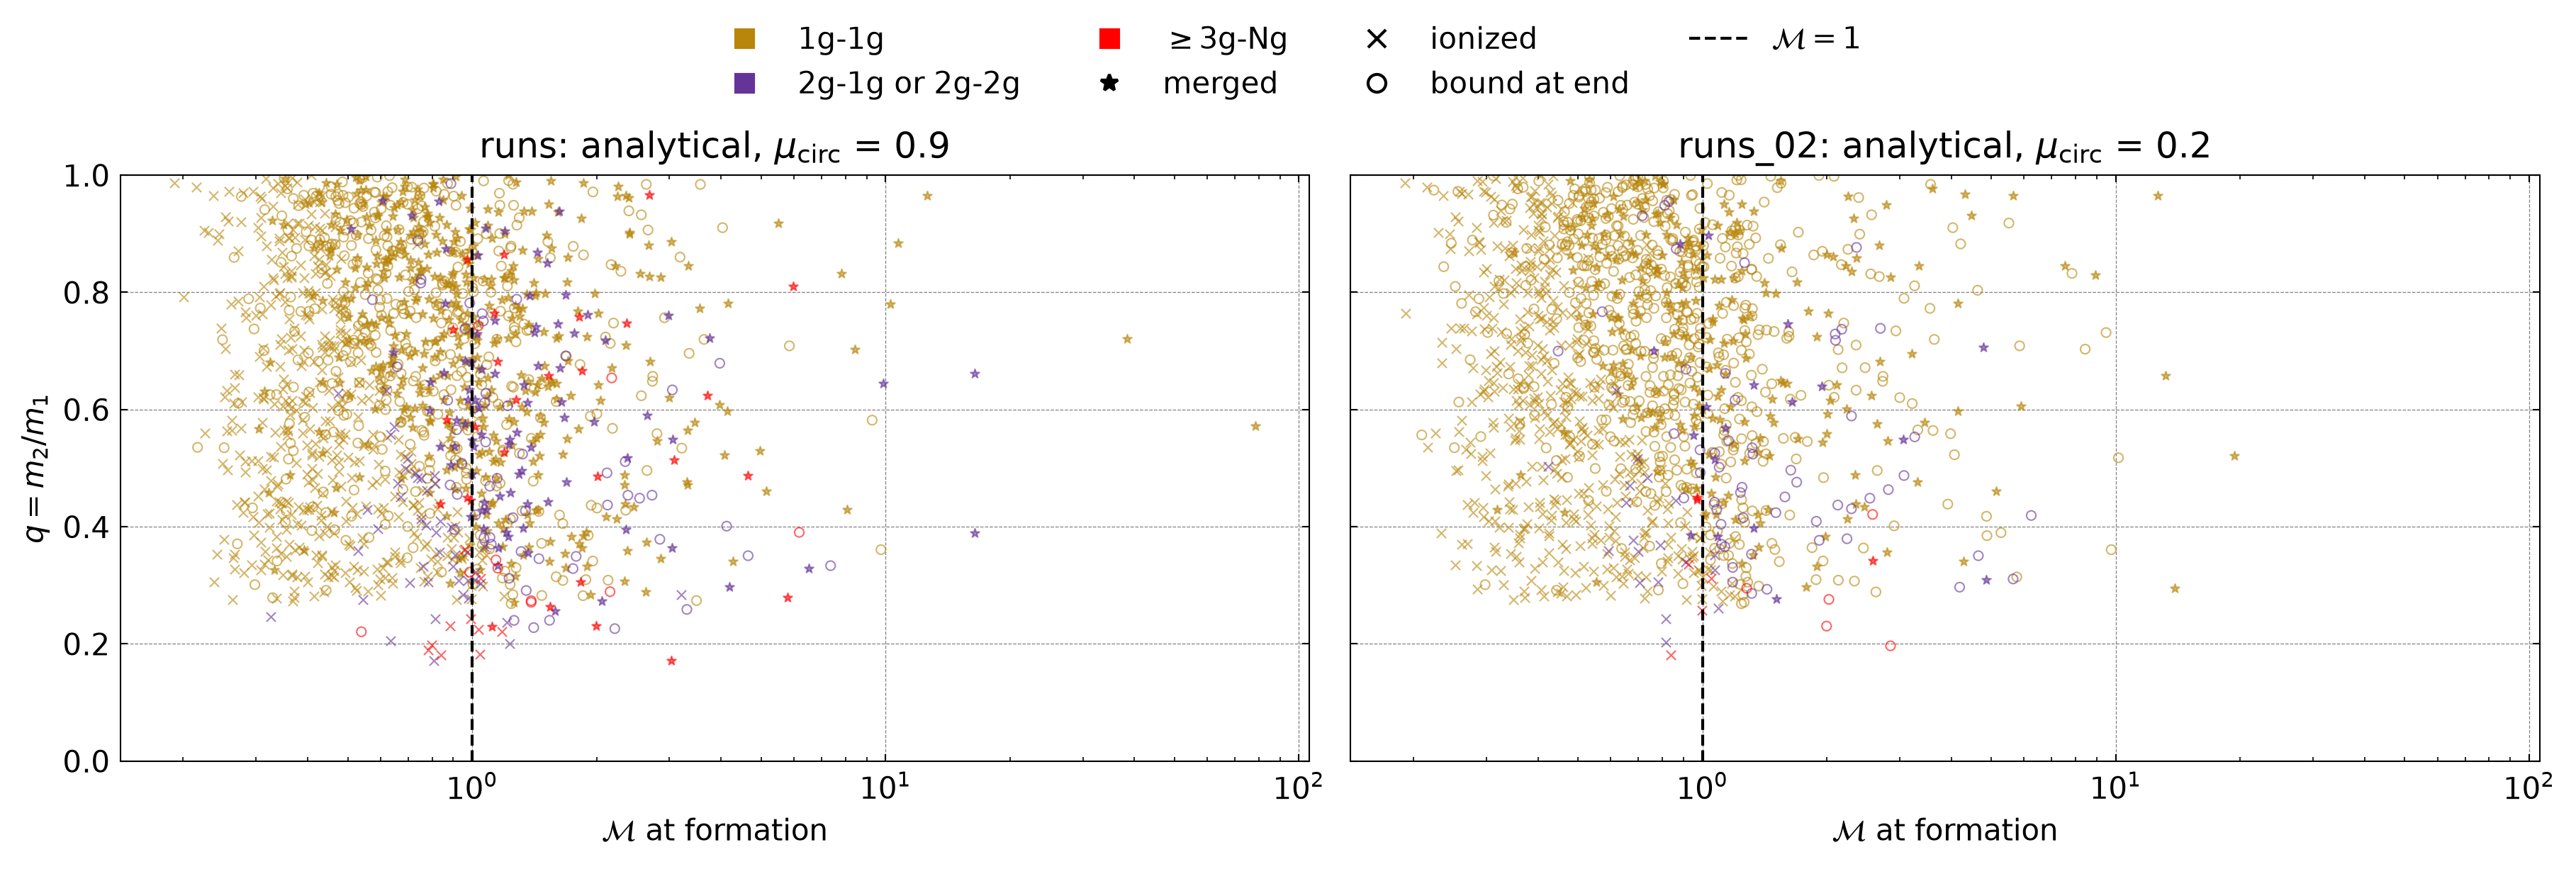

In [12]:
# fill: "solid" (filled marker), "line" (line-only marker like x), "open" (outline only)
FATE_STYLE = {
    "merged":  dict(marker="*", fill="solid", label="merged"),
    "ionized": dict(marker="x", fill="line",  label="ionized"),
    "bound":   dict(marker="o", fill="open",  label="bound at end"),
}


def marker_colors(fill, color):
    if fill == "solid":
        return dict(facecolors=color, edgecolors=color)
    if fill == "open":
        return dict(facecolors="none", edgecolors=color)
    return dict(color=color)  # line-only markers have no face/edge distinction
GENS = ("gen1", "gen2", "genX")
GEN_LABELS = ("1g-1g", "2g-1g or 2g-2g", r"$\geq$3g-Ng")
MARKER_SIZE = 10


def draw_fates(ax, fates):
    gen_masks = make_gen_masks(fates.gen_1.to_numpy(), fates.gen_2.to_numpy())
    for gen, gen_mask in zip(GENS, gen_masks):
        color = getattr(styles, f"color_{gen}")
        for fate, style in FATE_STYLE.items():
            sel = gen_mask & (fates.fate == fate).to_numpy()
            ax.scatter(fates.mach[sel], fates.q[sel], s=MARKER_SIZE, marker=style["marker"], linewidths=0.5,
                       alpha=getattr(styles, f"markeralpha_{gen}"), **marker_colors(style["fill"], color))

    ax.axvline(1, color="k", ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_ylim(0, 1)
    ax.grid(True, color="gray", ls="dashed", lw=0.3)
    ax.set_axisbelow(True)


def legend_handles():
    # Colour = generation, marker = fate; proxies keep the legend compact
    gen = [Line2D([], [], ls="none", marker="s", color=getattr(styles, f"color_{g}"), label=lbl)
           for g, lbl in zip(GENS, GEN_LABELS)]
    fate = [Line2D([], [], ls="none", marker=st["marker"], color="k",
                   markerfacecolor="none" if st["fill"] == "open" else "k", label=st["label"]) for st in FATE_STYLE.values()]
    return gen + fate + [Line2D([], [], color="k", ls="--", lw=1, label=r"$\mathcal{M} = 1$")]


n = len(FATES)
fig, axes = plt.subplots(1, n, sharex=True, sharey=True, squeeze=False,
                         figsize=(12, 4), constrained_layout=True)

for ax, (run_dir, fates) in zip(axes[0], FATES.items()):
    s = SETTINGS[run_dir]
    draw_fates(ax, fates)
    ax.set_title(rf"{os.path.basename(os.path.normpath(run_dir))}: {s.gas_hardening_prescription}, "
                 rf"$\mu_{{\rm circ}}$ = {s.mu_circ_encounter}")
    ax.set_xlabel(r"$\mathcal{M}$ at formation")
axes[0, 0].set_ylabel(r"$q = m_2/m_1$")
fig.legend(handles=legend_handles(), loc="outside upper center", ncols=4, frameon=False)

os.makedirs(FIG_DIR, exist_ok=True)
for ext in FORMATS:
    fig.savefig(os.path.join(FIG_DIR, f"q_mach_fates.{ext}"), dpi=300 if ext == "png" else None)
plt.show()